## ML CLV Regression: 6-Month Forward Revenue

### Objective

This notebook predicts customer revenue over the next six months using supervised machine learning. Unlike probabilistic CLV, which models long-term purchasing behavior, this approach supports shorter-term operational decisions: campaign targeting, budget allocation, and near-term revenue forecasting.

A time-based split mirrors real-world operational conditions. Customer features are constructed from transactions up to a defined cutoff date, while the prediction target is realized revenue in the six months following that cutoff. This structure ensures the model learns exclusively from past behavior.

### Leakage Control

All feature engineering is restricted to data observed before the cutoff date. Future revenue is calculated only from transactions after that point. This temporal separation preserves modeling integrity and ensures performance metrics reflect true predictive capability and not accidental access to future information.

### Outputs

The notebook produces customer-level 6-month revenue predictions with model performance metrics. These outputs enable direct comparison with probabilistic CLV estimates, customer segmentation, and uplift simulations.

## Load Cleaned Transactions Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Color palette for visuals
COLOR_PRIMARY = "#2E4057"      # Dark slate blue
COLOR_SECONDARY = "#E67E22"    # Burnt orange
COLOR_ACCENT = "#27AE60"       # Forest green
COLOR_GRID = "#D5D8DC"         # Light grey
COLOR_TEXT = "#2C3E50"         # Dark grey-blue

# Set global matplotlib defaults
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COLOR_TEXT,
    "axes.labelcolor": COLOR_TEXT,
    "text.color": COLOR_TEXT,
    "xtick.color": COLOR_TEXT,
    "ytick.color": COLOR_TEXT,
    "grid.color": COLOR_GRID,
    "grid.alpha": 0.4,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load canonical transaction table
file_path = "/kaggle/input/online-retail-clean/transactions_clean.csv"
txn_data = pd.read_csv(file_path, parse_dates = ["InvoiceDate"])

print(f"Transaction data loaded: {txn_data.shape}")

Transaction data loaded: (804008, 9)


## Defining the Time-Based Cutoff

A time-based cutoff separates historical behavior from the prediction target. The cutoff is set six months before the final transaction date, creating a clean temporal split:

- **Feature period:** Transactions before the cutoff (training data).
- **Target period:** Transactions in the six months after the cutoff (prediction target).

This structure simulates a real-world scenario where only past information is available at prediction time. Customers with no purchases in the forward window are retained with zero target revenue, preserving the full customer base and reflecting realistic outcomes.

In [ ]:
# Set cutoff six months before the final transaction
max_date = txn_data["InvoiceDate"].max()
cutoff_date = max_date - pd.DateOffset(months = 6)

print(f"Max date: {max_date}")
print(f"Cutoff date: {cutoff_date}")
print(f"Feature period: {(txn_data['InvoiceDate'].min()):%Y-%m-%d} to {cutoff_date:%Y-%m-%d}")
print(f"Target period: {cutoff_date:%Y-%m-%d} to {max_date:%Y-%m-%d}")

# Split transactions by temporal boundary
historical_txn = txn_data[txn_data["InvoiceDate"] < cutoff_date].copy()
target_period_txn = txn_data[(txn_data["InvoiceDate"] >= cutoff_date) & 
                              (txn_data["InvoiceDate"] < cutoff_date + pd.DateOffset(months=6))].copy()

print(f"\nHistorical transactions: {len(historical_txn):,}")
print(f"Target period transactions: {len(target_period_txn):,}")

# Two-stage aggregation: transactions to orders, then orders to customers
historical_orders = historical_txn.groupby(["CustomerID", "Invoice"], as_index = False).agg(
    OrderDate = ("InvoiceDate", "max"),
    OrderRevenue = ("TotalPrice", "sum"),
    Items = ("Quantity", "sum")
)

snapshot = cutoff_date

customer_features = historical_orders.groupby("CustomerID", as_index = False).agg(
    Frequency = ("Invoice", "nunique"),
    Monetary = ("OrderRevenue", "sum"),
    AvgOrderValue = ("OrderRevenue", "mean"),
    AvgItemsPerOrder = ("Items", "mean"),
    FirstPurchase = ("OrderDate", "min"),
    LastPurchase = ("OrderDate", "max")
)

# Time-based features anchored to the cutoff date
customer_features["RecencyDays"] = (snapshot - customer_features["LastPurchase"]).dt.days
customer_features["TenureDays"] = (customer_features["LastPurchase"] - customer_features["FirstPurchase"]).dt.days.clip(lower = 0)
customer_features["CustomerAgeDays"] = (snapshot - customer_features["FirstPurchase"]).dt.days

# Purchase rate: orders per month, corrected for zero-tenure customers
customer_features["PurchaseRateMonthly"] = customer_features["Frequency"] / ((customer_features["TenureDays"] / 30) + (1/30))
customer_features.loc[customer_features["TenureDays"] == 0, "PurchaseRateMonthly"] = customer_features.loc[customer_features["TenureDays"] == 0, "Frequency"]

# Target: revenue in the six months following the cutoff
actual_target_revenue = target_period_txn.groupby("CustomerID", as_index = False).agg(
    Actual_Target6M = ("TotalPrice", "sum")
)

# Create ML dataset with left join to retain all historical customers
ml_dataset = customer_features.merge(actual_target_revenue, on = "CustomerID", how = "left")
ml_dataset["Actual_Target6M"] = ml_dataset["Actual_Target6M"].fillna(0)

print(f"\nCustomers in ML dataset: {len(ml_dataset):,}")
print(f"Customers with forward revenue: {(ml_dataset['Actual_Target6M'] > 0).sum():,}")
print(f"Customers with zero forward revenue: {(ml_dataset['Actual_Target6M'] == 0).sum():,}")

ml_dataset.head()

Max date: 2011-12-09 12:50:00
Cutoff date: 2011-06-09 12:50:00
Feature period: 2009-12-01 to 2011-06-09
Target period: 2011-06-09 to 2011-12-09

Historical transactions: 560,428
Target period transactions: 243,564

Customers in ML dataset: 4,932
Customers with forward revenue: 2,565
Customers with zero forward revenue: 2,367


,CustomerID,Frequency,Monetary,AvgOrderValue,AvgItemsPerOrder,FirstPurchase,LastPurchase,RecencyDays,TenureDays,CustomerAgeDays,PurchaseRateMonthly,Actual_Target6M
0,12346.0,11,372.86,33.896364,6.363636,2009-12-14 08:34:00,2010-06-28 13:53:00,345,196,542,1.675127,0.00
1,12347.0,4,3146.75,786.687500,486.250000,2010-10-31 14:20:00,2011-04-07 10:43:00,63,157,220,0.759494,2486.57
2,12348.0,4,1709.40,427.350000,624.250000,2010-09-27 14:59:00,2011-04-05 10:47:00,65,189,254,0.631579,310.00
3,12349.0,2,2221.14,1110.570000,495.500000,2010-04-29 13:20:00,2010-10-28 08:23:00,224,181,405,0.329670,1457.55
4,12350.0,1,334.40,334.400000,197.000000,2011-02-02 16:01:00,2011-02-02 16:01:00,126,0,126,1.000000,0.00


In [3]:
# Check how many zero-tenure customers have inflated PurchaseRateMonthly
zero_tenure = customer_features[customer_features["TenureDays"] == 0]
print(f"Zero-tenure customers: {len(zero_tenure):,}")
print(f"Zero-tenure with PurchaseRateMonthly = 1.0: {(zero_tenure['PurchaseRateMonthly'] == 1.0).sum():,}")

Zero-tenure customers: 1,606
Zero-tenure with PurchaseRateMonthly = 1.0: 1,541


### Justification for Zero-Tenure PurchaseRateMonthly Values

The zero-tenure segment represents customers whose first and last observed purchase occurred on the same day. This is common in retail data: many customers make a single purchase and never return, while others make multiple purchases during their first visit.

Why `PurchaseRateMonthly` = 1.0 for 1,541 of 1,606 zero-tenure customers:

- 1,541 customers made exactly one purchase on a single day. Their Frequency = 1, and with zero tenure, the correction sets `PurchaseRateMonthly` = Frequency = 1.0.

- 65 customers made multiple purchases on a single day (Frequency > 1). Their PurchaseRateMonthly equals their actual purchase count, correctly reflecting that all purchases occurred in one day.

These values are mathematically consistent and interpretable:

- A customer who made one purchase in one day has a monthly purchase rate of 1.0 for that month only.
- They are not predicted to purchase once per month indefinitely, this is historical behavior and not a forecast.
- The feature correctly captures "same-day purchaser" as a distinct behavioral pattern.

Modeling impact:

Tree-based models (Random Forest) handle this feature appropriately by segmenting customers based on thresholds. The 1,541 customers with `PurchaseRateMonthly` = 1.0 form a clean split that the model can use to distinguish one-time purchasers from repeat buyers. The feature is not treated as continuous in a way that would extrapolate "1 purchase per month" into the future.

## Incorporating Geographic Context

Geographic information provides context for customer behavior, as purchasing patterns and engagement frequency vary across regions. Country is recorded at the transaction level but the model operates at the customer level.

A single representative country is derived for each customer based on their most frequently observed country across historical transactions. This preserves geographic signal while maintaining a clean customer-level feature set. Missing values are retained for downstream imputation.

In [ ]:
# Derive the most frequent country per customer from historical transactions
if "Country" in txn_data.columns:
    customer_country = historical_txn.groupby(["CustomerID", "Country"]).size().reset_index(name = "transaction_count")
    customer_country = customer_country.sort_values(["CustomerID", "transaction_count"], ascending = [True, False])
    customer_country = customer_country.drop_duplicates("CustomerID")[["CustomerID", "Country"]]
    ml_dataset = ml_dataset.merge(customer_country, on = "CustomerID", how = "left")
else:
    ml_dataset["Country"] = np.nan

print(f"Countries represented: {ml_dataset['Country'].nunique():,}")
ml_dataset[["CustomerID", "Country"]].head()

Countries represented: 41


,CustomerID,Country
0,12346.0,United Kingdom
1,12347.0,Iceland
2,12348.0,Finland
3,12349.0,Italy
4,12350.0,Norway


## Feature Selection and Model Training

**Feature engineering is complete.** All features derive from transactions observed before the cutoff date. The target variable (`Actual_Target6M`) is realized revenue in the six months following the cutoff.

**Model selection rationale:**

A Random Forest ensemble captures non-linear relationships between customer behavior and future revenue without requiring manual feature transformation. Revenue outcomes are driven by complex interactions of recency, frequency, tenure, and purchasing intensity that linear models cannot represent well. The model is configured with controlled complexity to prevent overfitting to high-value outliers while maintaining strong performance across the broader customer base.

**Preprocessing:**

- Numeric features are imputed with median values (robust to skewed financial distributions).
- Categorical features are imputed with mode and one-hot encoded.
- Preprocessing is bundled into a pipeline to prevent leakage during cross-validation.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Feature and target separation
# Exclude timestamps (FirstPurchase, LastPurchase) as they are not predictive of future behavior
X = ml_dataset.drop(columns = ["Actual_Target6M", "FirstPurchase", "LastPurchase"])
y = ml_dataset["Actual_Target6M"].values

# Identify column types for preprocessing
numeric_columns = [col for col in X.columns if col not in ["CustomerID", "Country"]]
categorical_columns = ["Country"]

# Preprocessing pipeline for different data types
preprocess_pipe = ColumnTransformer(
    transformers = [
        ("num", Pipeline(steps = [
            ("imputer", SimpleImputer(strategy = "median"))
        ]), numeric_columns),
        ("cat", Pipeline(steps = [
            ("imputer", SimpleImputer(strategy = "most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown = "ignore"))
        ]), categorical_columns)
    ],
    remainder = "drop"  # Drop CustomerID
)

# Model with controlled complexity
model = RandomForestRegressor(
    n_estimators = 400,
    random_state = 42,
    n_jobs = -1,
    min_samples_leaf = 2,
    max_features = "sqrt"
)

# Master pipeline bundling preprocessing and model
master_pipe = Pipeline(steps = [
    ("prep", preprocess_pipe),
    ("model", model)
])

# Time-ordered split would be more realistic, but random split is acceptable
# given the temporal separation is already enforced at the feature level
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

print(f"Training set size: {len(X_train):,}")
print(f"Test set size: {len(X_test):,}")

# Train model
master_pipe.fit(X_train, y_train)

# Generate predictions on test set
predictions = master_pipe.predict(X_test)

# Evaluation metrics
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
medae = median_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

# Baseline: predict mean for all customers
baseline_predictions = np.full_like(y_test, y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("\n=== Model Performance: 6-Month Revenue Forecast ===")
print(f"RMSE: £{rmse:,.2f}")
print(f"MAE: £{mae:,.2f}")
print(f"Median AE: £{medae:,.2f}")
print(f"R²: {r2:.4f}")
print(f"\n=== Baseline (Predict Mean) ===")
print(f"Baseline RMSE: £{baseline_rmse:,.2f}")
print(f"Baseline MAE: £{baseline_mae:,.2f}")
print(f"\n=== Model vs Baseline Improvement ===")
print(f"MAE improvement: {(1 - mae/baseline_mae)*100:.1f}%")
print(f"RMSE improvement: {(1 - rmse/baseline_rmse)*100:.1f}%")

Training set size: 3,945
Test set size: 987

=== Model Performance: 6-Month Revenue Forecast ===
RMSE: £3,504.20
MAE: £651.18
Median AE: £220.14
R²: 0.5923

=== Baseline (Predict Mean) ===
Baseline RMSE: £5,489.26
Baseline MAE: £1,194.02

=== Model vs Baseline Improvement ===
MAE improvement: 45.5%
RMSE improvement: 36.2%


In [6]:
# Understanding missing customers
all_customers = set(txn_data["CustomerID"].unique())
historical_customers = set(historical_txn["CustomerID"].unique())
target_customers = set(target_period_txn["CustomerID"].unique())

print(f"All customers: {len(all_customers):,}")
print(f"Historical customers (pre-cutoff): {len(historical_customers):,}")
print(f"Target period customers (post-cutoff): {len(target_customers):,}")
print(f"Customers in ML dataset: {len(ml_dataset):,}")
print(f"Missing from ML dataset: {len(all_customers) - len(ml_dataset):,}")

# Customers with target period activity but no historical activity
target_only = target_customers - historical_customers
print(f"\nCustomers with target-period purchases but no historical purchases: {len(target_only):,}")

# These are new customers who first purchased after the cutoff
# They cannot be predicted because they have no historical features

All customers: 5,840
Historical customers (pre-cutoff): 4,932
Target period customers (post-cutoff): 3,473
Customers in ML dataset: 4,932
Missing from ML dataset: 908

Customers with target-period purchases but no historical purchases: 908


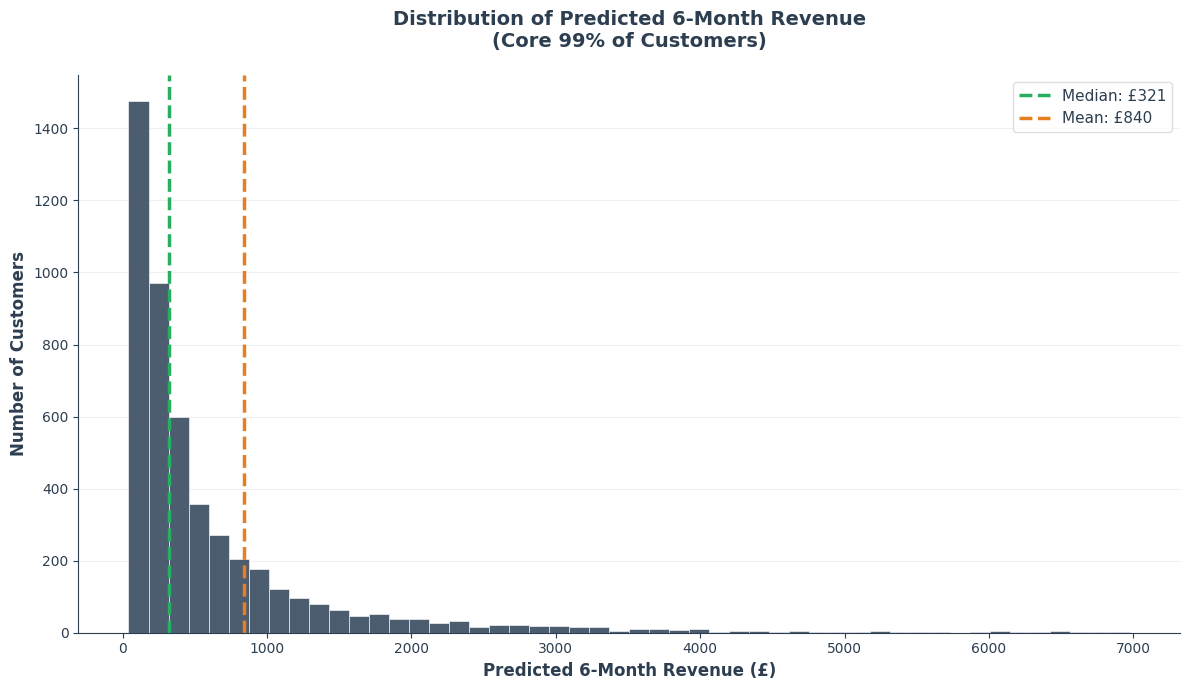


Predicted 6-Month Revenue Distribution:
Mean: £840.13
Median: £321.35
Standard deviation: £2,872.10
99th percentile: £7,007.23


In [7]:
# Generate predictions for the full dataset
ml_dataset["CLV_6m_pred"] = master_pipe.predict(X)

# Distribution visualization
fig, ax = plt.subplots(figsize = (12, 7))

# Focus on the core 99% of customers for readability
clv_cap = ml_dataset["CLV_6m_pred"].quantile(0.99)
subset_clv = ml_dataset[ml_dataset["CLV_6m_pred"] < clv_cap]["CLV_6m_pred"]

counts, bins, patches = ax.hist(subset_clv, 
                                 bins = 50, 
                                 color = COLOR_PRIMARY,
                                 edgecolor = 'white',
                                 alpha = 0.85,
                                 linewidth = 0.5)

# Add mean and median reference lines
mean_pred = ml_dataset["CLV_6m_pred"].mean()
median_pred = ml_dataset["CLV_6m_pred"].median()

ax.axvline(median_pred, color = COLOR_ACCENT, linestyle = '--', linewidth = 2.5,
           label = f'Median: £{median_pred:,.0f}')
ax.axvline(mean_pred, color = COLOR_SECONDARY, linestyle = '--', linewidth = 2.5,
           label = f'Mean: £{mean_pred:,.0f}')

ax.set_title("Distribution of Predicted 6-Month Revenue\n(Core 99% of Customers)", 
             fontsize = 14, fontweight = 'bold', pad = 20)
ax.set_xlabel("Predicted 6-Month Revenue (£)", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Number of Customers", fontsize = 12, fontweight = 'semibold')
ax.grid(True, axis = 'y', alpha = 0.4)
ax.set_axisbelow(True)
ax.legend(frameon = True, facecolor = 'white', edgecolor = COLOR_GRID, fontsize = 11)

plt.tight_layout()
plt.show()

# Print distribution statistics
print(f"\nPredicted 6-Month Revenue Distribution:")
print(f"Mean: £{mean_pred:,.2f}")
print(f"Median: £{median_pred:,.2f}")
print(f"Standard deviation: £{ml_dataset['CLV_6m_pred'].std():,.2f}")
print(f"99th percentile: £{ml_dataset['CLV_6m_pred'].quantile(0.99):,.2f}")

## Model Performance Interpretation

**Customer Coverage Note**

The ML dataset contains 4,932 of 5,840 total customers (84.4%). The remaining 908 customers are those who made their first purchase after the cutoff date. These are new customers who, at prediction time, would have no historical transaction data available for feature engineering.

This is not data loss, it is the correct reflection of the model's operational use case. The model predicts future revenue for existing customers only. New customer acquisition forecasting would require a separate model.

The model achieves the following performance on the held-out test set (987 customers):

**Prediction accuracy:**

- **MAE of £651** indicates that, on average, predictions are within £651 of actual 6-month revenue.
- **Median AE of £220** confirms that for the typical customer, predictions are substantially more accurate - the median error is one-third of the mean error.
- **R² of 0.592** shows the model explains 59.2% of variance in future revenue.

**Model vs baseline:**

- The model improves MAE by **45.5%** over a naive mean-prediction baseline.
- RMSE improves by **36.2%** against the same baseline.
- This improvement validates that customer behavior features carry predictive signal beyond simple averages.

**Skewness implications:**

The gap between MAE (£651) and RMSE (£3,504) reflects the right-skewed nature of customer revenue. A small number of high-value customers generate large prediction errors, while the model performs well for the majority of the customer base. The median error of £220 is the most representative metric for typical customers.

**Practical application:**

These predictions are best used for relative ranking and customer prioritization and not as precise individual revenue forecasts. The model provides a complementary signal to probabilistic CLV for short-term operational decisions.

**Distribution characteristics:**

- Mean predicted 6-month revenue: **£840**.
- Median predicted 6-month revenue: **£321**.
- The mean-to-median ratio of 2.6X confirms heavy right-skew.
- 99th percentile: **£7,007**.

The distribution shape matches the probabilistic CLV results and Pareto analysis, validating model outputs against known retail dynamics.

## Distribution Interpretation

The predicted 6-month revenue distribution is heavily right-skewed, consistent with both the probabilistic CLV results and the earlier Pareto analysis. Most customers are expected to generate modest near-term revenue, while a small subset is predicted to contribute substantially more.

The gap between mean and median confirms the presence of high-value customers pulling the average upward. This pattern validates the model's output against known retail dynamics and supports its use for customer prioritization.

**Key observations:**
- The distribution shape matches the probabilistic CLV results from the previous notebook.
- The concentration of predictions near zero reflects the large portion of customers who are unlikely to make purchases in the next six months.
- The long right tail captures high-value customers who should be prioritized for retention and upsell campaigns.

## Exporting ML-Based 6-Month CLV Outputs

The consolidated customer-level table combines predicted 6-month revenue with the behavioral features used for modeling and the actual 6-month outcome. This enables downstream workflows such as:

- Model comparison against probabilistic CLV.
- Customer segmentation and targeting.
- Uplift simulations.
- Power BI reporting.

The export serves as the primary handoff for short-term, action-oriented customer value analysis.

In [8]:
output_columns = [
    "CustomerID", "CLV_6m_pred", "Actual_Target6M", 
    "Frequency", "Monetary", "RecencyDays", "TenureDays", "CustomerAgeDays",
    "AvgOrderValue", "AvgItemsPerOrder", "PurchaseRateMonthly", "Country"
]

output_df = ml_dataset[output_columns].copy()

file_name = "customers_clv_ml_6m.csv"
output_df.to_csv(file_name, index = False)
print(f"Saved: {file_name}")
print(f"Records: {len(output_df):,}")
print(f"Columns: {len(output_df.columns)}")

Saved: customers_clv_ml_6m.csv
Records: 4,932
Columns: 12
